In [39]:
import pandas as pd

In [40]:
df = pd.read_csv("../data/raw/services-2026-09.csv")
df.shape

(1863470, 20)

In [41]:
df.head()

,Service:RDT-ID,Service:Date,Service:Type,Service:Company,Service:Train number,Service:Completely cancelled,Service:Partly cancelled,Service:Maximum delay,Stop:RDT-ID,Stop:Station code,Stop:Station name,Stop:Arrival time,Stop:Arrival delay,Stop:Arrival cancelled,Stop:Departure time,Stop:Departure delay,Stop:Departure cancelled,Stop:Platform change,Stop:Planned platform,Stop:Actual platform
0,19102256,2026-09-01,Stoptrein,DB,20236,False,False,1470,173431642,MUNST,Münster (Westf) Hbf,NaN,NaN,NaN,2026-08-31T23:08:00+02:00,1448.0,False,False,4,4
1,19102256,2026-09-01,Stoptrein,DB,20236,False,False,24,173431643,ENHF,Münster (W) Zentrum Nord,2026-08-31T23:13:00+02:00,1450.0,False,2026-08-31T23:14:00+02:00,1450.0,False,False,2,2
2,19102256,2026-09-01,Stoptrein,DB,20236,False,False,0,173431644,ENBE,Münster-Häger,2026-08-31T23:19:00+02:00,1449.0,False,2026-08-31T23:20:00+02:00,1449.0,False,False,1,1
3,19102256,2026-09-01,Stoptrein,DB,20236,False,False,0,173431645,EABG,Altenberge,2026-08-31T23:25:00+02:00,1449.0,False,2026-08-31T23:26:00+02:00,1449.0,False,False,2,2
4,19102256,2026-09-01,Stoptrein,DB,20236,False,False,0,173431646,ENOW,Nordwalde,2026-08-31T23:29:00+02:00,1448.0,False,2026-08-31T23:29:00+02:00,1448.0,False,False,1,1


In [42]:
df.columns.tolist()


['Service:RDT-ID',
 'Service:Date',
 'Service:Type',
 'Service:Company',
 'Service:Train number',
 'Service:Completely cancelled',
 'Service:Partly cancelled',
 'Service:Maximum delay',
 'Stop:RDT-ID',
 'Stop:Station code',
 'Stop:Station name',
 'Stop:Arrival time',
 'Stop:Arrival delay',
 'Stop:Arrival cancelled',
 'Stop:Departure time',
 'Stop:Departure delay',
 'Stop:Departure cancelled',
 'Stop:Platform change',
 'Stop:Planned platform',
 'Stop:Actual platform']

In [43]:
df.isna().mean().sort_values(ascending=False)
# df.duplicated().sum()

Stop:Actual platform            0.122268
Stop:Planned platform           0.122268
Stop:Departure cancelled        0.101908
Stop:Departure delay            0.101908
Stop:Departure time             0.101908
Stop:Arrival time               0.101883
Stop:Arrival cancelled          0.101883
Stop:Arrival delay              0.101883
Stop:Station code               0.001198
Stop:Platform change            0.000000
Service:RDT-ID                  0.000000
Service:Date                    0.000000
Stop:RDT-ID                     0.000000
Service:Maximum delay           0.000000
Service:Partly cancelled        0.000000
Service:Completely cancelled    0.000000
Service:Train number            0.000000
Service:Company                 0.000000
Service:Type                    0.000000
Stop:Station name               0.000000
dtype: float64

In [44]:
df.describe()                          # numeric columns: min, max, mean
                # how many distinct values per column

,Service:RDT-ID,Service:Train number,Service:Maximum delay,Stop:RDT-ID,Stop:Arrival delay,Stop:Departure delay
count,1.863470e+06,1.863470e+06,1.863470e+06,1.863470e+06,1.673615e+06,1.673567e+06
mean,1.919787e+07,3.674503e+04,2.347749e-01,1.743687e+08,1.178812e+00,1.108584e+00
std,5.509256e+04,1.327594e+05,5.967349e+00,5.384535e+05,2.170985e+01,2.166496e+01
min,1.910226e+07,1.200000e+02,0.000000e+00,1.734316e+08,0.000000e+00,0.000000e+00
25%,1.915056e+07,4.097000e+03,0.000000e+00,1.739028e+08,0.000000e+00,0.000000e+00
50%,1.919813e+07,6.630000e+03,0.000000e+00,1.743687e+08,0.000000e+00,0.000000e+00
75%,1.924570e+07,2.023200e+04,0.000000e+00,1.748346e+08,1.000000e+00,1.000000e+00
max,1.931092e+07,9.720870e+05,1.470000e+03,1.754827e+08,1.470000e+03,1.452000e+03


In [45]:
# Keep only rows that have a departure (the last stop of a trip has none)
dep = df[df["Stop:Departure time"].notna()].copy()

# Cancellations: how common are they?
dep["Stop:Departure cancelled"].mean()

# Target, using non-cancelled departures only
ok = dep[~dep["Stop:Departure cancelled"].astype(bool)].copy()
ok["late"] = ok["Stop:Departure delay"] >= 5
ok["late"].mean()

np.float64(0.04259771022502961)

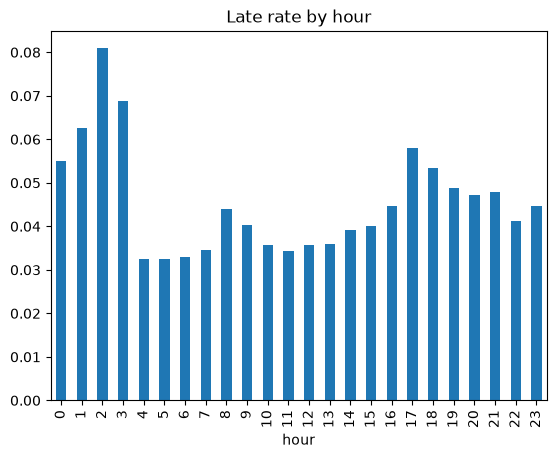

In [46]:
ok["dep_time"] = pd.to_datetime(ok["Stop:Departure time"])
ok["hour"] = ok["dep_time"].dt.hour
ok["weekday"] = ok["dep_time"].dt.dayofweek

ok.groupby("hour")["late"].mean().plot(kind="bar", title="Late rate by hour")
ok.groupby("Service:Type")["late"].agg(["mean", "count"]).sort_values("count", ascending=False)
ok.groupby("Stop:Station name")["late"].agg(["mean", "count"]).sort_values("count", ascending=False).head(20)

In [47]:
df["Service:RDT-ID"].nunique()

189757

In [48]:
dep["Stop:Departure cancelled"].mean()

np.float64(0.07674446257604267)

In [49]:
dep["disrupted"] = dep["Stop:Departure cancelled"].astype(bool) | (dep["Stop:Departure delay"] >= 5)
dep["disrupted"].mean()

np.float64(0.11607303442288239)

In [50]:
ok.groupby("hour")["late"].agg(["mean", "count"])

,mean,count
hour,,
0,0.055014,41462
1,0.062527,9148
2,0.080893,1434
3,0.068759,669
4,0.032412,1049
5,0.032468,20851
6,0.033060,63582
7,0.034665,83715
8,0.044011,87841


In [51]:
ok["Stop:Departure time"].head()
ok.loc[ok['hour'] == 0, "Stop:Departure time"].sample(10)

196663     2026-09-04T00:35:00+02:00
863534     2026-09-15T00:21:00+02:00
434698     2026-09-08T00:49:00+02:00
692444     2026-09-12T00:05:00+02:00
793226     2026-09-14T00:36:00+02:00
630064     2026-09-11T00:34:00+02:00
1666314    2026-09-28T00:46:00+02:00
1495786    2026-09-25T00:50:00+02:00
1063047    2026-09-18T00:12:00+02:00
797814     2026-09-14T00:39:00+02:00
Name: Stop:Departure time, dtype: str

In [53]:
ok["dep_time"] = pd.to_datetime(ok["Stop:Departure time"], utc=True).dt.tz_convert("Europe/Amsterdam")